In [49]:
import os
import re
import json
import pandas as pd
import numpy as np
from dfft.utils.files import get_path


In [50]:

# Helper functions
def extract_time(d):
    m = re.match(r"(\d{8}_\d{6})", os.path.basename(d))
    return m.group(1) if m else ""

def extract_learning_rate(exp_dir_name):
    m = re.search(r"_lr_([0-9]*\.?[0-9]+(?:e-?[0-9]+)?)", exp_dir_name, re.IGNORECASE)
    if not m:
        return None
    return float(m.group(1))

def get_latest_experiments_by_lr(base_dir):
    if not os.path.isdir(base_dir):
        return []
    
    latest_by_lr = {}
    for d in os.listdir(base_dir):
        exp_dir = os.path.join(base_dir, d)
        if not os.path.isdir(exp_dir):
            continue
            
        lr = extract_learning_rate(d)
        if lr is None:
            continue
            
        ts = extract_time(d)
        if lr not in latest_by_lr or ts > latest_by_lr[lr][0]:
            latest_by_lr[lr] = (ts, exp_dir)
            
    return [(lr, latest_by_lr[lr][1]) for lr in sorted(latest_by_lr.keys())]

def get_latest_exp(base_dir):
    if not os.path.isdir(base_dir):
        return None
        
    exp_dirs = [os.path.join(base_dir, d) for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    if not exp_dirs:
        return None
        
    exp_dirs = sorted(exp_dirs, key=extract_time, reverse=True)
    return exp_dirs[0]

In [51]:
# 1. NonTSFM All Results
families = ["linear", "mlp", "lstm", "gru", "tcn"]
variants = ["small", "base", "large"]
loss_variants = ["", "-decision"]

nontsfm_models = []
for family in families:
    for variant in variants:
        for losser in loss_variants:
            nontsfm_models.append(f"{family}-{variant}{losser}")

all_nontsfm_results = []
for model in nontsfm_models:
    base_dir = get_path(f"nontsfm\\{model}\\NEMA")
    for learning_rate, exp_dir in get_latest_experiments_by_lr(base_dir):
        try:
            with open(exp_dir + "/results.json", 'r') as f:
                data = json.load(f)
            df_parquet = pd.read_parquet(exp_dir + "/results.parquet")
            
            sums = df_parquet.groupby('split')[['true_profit', 'real_profit']].mean()
            regret = (sums['true_profit'] - sums['real_profit']) / sums['true_profit']
            regret = (regret * 100).round(2)
            
            all_nontsfm_results.append({
                'model': model,
                'learning_rate': learning_rate,
                'train_mse': data.get('final_train_results', {}).get('mse', np.nan),
                'val_mse': data.get('final_val_results', {}).get('mse', np.nan),
                'test_mse': data.get('test_results', {}).get('mse', np.nan),
                'train_profit': sums['real_profit'].get('train', np.nan),
                'val_profit': sums['real_profit'].get('val', np.nan),
                'test_profit': sums['real_profit'].get('test', np.nan),
                'train_regret': regret.get('train', np.nan),
                'val_regret': regret.get('val', np.nan),
                'test_regret': regret.get('test', np.nan)
            })
        except Exception as e:
            pass

df_nontsfm = pd.DataFrame(all_nontsfm_results)
if not df_nontsfm.empty:
    df_nontsfm = df_nontsfm.sort_values(['model', 'learning_rate']).reset_index(drop=True)
    df_nontsfm[[ 'train_mse', 'val_mse', 'test_mse', 'train_profit', 'val_profit', 'test_profit', 'train_regret', 'val_regret', 'test_regret' ]] = df_nontsfm[[ 'train_mse', 'val_mse', 'test_mse', 'train_profit', 'val_profit', 'test_profit', 'train_regret', 'val_regret', 'test_regret' ]].round(2)
df_nontsfm

,model,learning_rate,train_mse,val_mse,test_mse,train_profit,val_profit,test_profit,train_regret,val_regret,test_regret
0,gru-base,0.0001,5241.56,2993.41,7271.92,8.68,6.76,19.44,95.39,95.77,92.06
1,gru-base,0.0010,3142.85,1738.50,4575.96,44.65,38.81,45.58,76.27,75.69,81.38
2,gru-base,0.0100,1515.73,1182.07,1939.21,87.10,69.61,106.07,53.71,56.39,56.68
3,gru-base-decision,0.0001,5602.91,3247.33,7703.96,88.57,67.69,112.61,52.93,57.60,54.01
4,gru-base-decision,0.0010,5573.91,3227.35,7670.52,50.98,44.81,64.57,72.91,71.93,73.63
...,...,...,...,...,...,...,...,...,...,...,...
85,tcn-small,0.0010,1057.73,1166.45,1289.26,86.82,70.23,116.99,53.86,56.01,52.22
86,tcn-small,0.0100,1025.33,1160.05,1283.13,90.87,71.77,116.52,51.71,55.04,52.41
87,tcn-small-decision,0.0001,5862.54,3390.81,8048.73,41.43,37.60,51.38,77.98,76.45,79.01
88,tcn-small-decision,0.0010,5342.59,3146.29,7316.78,62.80,51.32,78.13,66.63,67.85,68.09


In [52]:
# 2. NonTSFM Filtered (Best val_profit)
if not df_nontsfm.empty:
    df_nontsfm_best = df_nontsfm.loc[df_nontsfm.groupby('model')['val_profit'].idxmax()].copy()
    df_nontsfm_best = df_nontsfm_best.drop(columns=['learning_rate']).reset_index(drop=True)
    
else:
    df_nontsfm_best = pd.DataFrame()

df_nontsfm_best

,model,train_mse,val_mse,test_mse,train_profit,val_profit,test_profit,train_regret,val_regret,test_regret
0,gru-base,1515.73,1182.07,1939.21,87.10,69.61,106.07,53.71,56.39,56.68
1,gru-base-decision,5555.89,3214.29,7648.05,88.68,72.26,116.52,52.87,54.74,52.41
2,gru-large,1215.06,1174.05,1561.18,89.09,69.13,111.17,52.66,56.70,54.60
3,gru-large-decision,5580.94,3232.22,7679.36,85.51,72.53,115.51,54.56,54.56,52.82
4,gru-small,1561.72,1198.58,2026.64,86.48,65.46,103.90,54.04,59.00,57.57
5,gru-small-decision,5623.47,3263.03,7732.32,64.78,50.03,69.54,65.57,68.66,71.60
6,linear-base,775.77,1275.82,1428.95,117.00,50.59,95.06,37.82,68.31,61.18
7,linear-base-decision,57725.02,25483.95,83132.80,91.63,67.36,109.18,51.30,57.80,55.41
8,linear-large,810.78,1279.38,1409.59,107.37,45.50,82.18,42.94,71.50,66.44
9,linear-large-decision,53376.89,23513.18,76222.10,89.15,65.35,113.22,52.62,59.06,53.76


In [53]:
# 3. TSFM Models Results
experiments_path = get_path("results\\experiments")
if os.path.isdir(experiments_path):
    tsfm_models = [d for d in os.listdir(experiments_path) if os.path.isdir(os.path.join(experiments_path, d))]
else:
    tsfm_models = []

all_tsfm_results = []
for model in tsfm_models:
    if "time" in model.lower():
        continue
    base_dir = os.path.join(experiments_path, model, "NEMA")
    exp_dir = get_latest_exp(base_dir)
    # print(f"Processing model: {model}, experiment dir: {exp_dir}")
    if not exp_dir: 
        continue
    
    try:
        with open(os.path.join(exp_dir, "results.json"), 'r') as f:
            data = json.load(f)
        df_parquet = pd.read_parquet(os.path.join(exp_dir, "results.parquet"))
        
        sums = df_parquet.groupby('split')[['true_profit', 'real_profit']].mean()
        regret = (sums['true_profit'] - sums['real_profit']) / sums['true_profit']
        regret = (regret * 100).round(1)
        
        all_tsfm_results.append({
            'model': model,
            'train_mse': data.get('final_train_results', {}).get('mse', np.nan),
            'val_mse': data.get('final_val_results', {}).get('mse', np.nan),
            'test_mse': data.get('test_results', {}).get('mse', np.nan),
            'train_profit': sums['real_profit'].get('train', np.nan),
            'val_profit': sums['real_profit'].get('val', np.nan),
            'test_profit': sums['real_profit'].get('test', np.nan),
            'train_regret': regret.get('train', np.nan),
            'val_regret': regret.get('val', np.nan),
            'test_regret': regret.get('test', np.nan)
        })
        # print(f"Successfully processed model: {model}")
    except Exception as e:
        print(f"Error processing model {model}: {e}")
        pass

df_tsfm = pd.DataFrame(all_tsfm_results)
if not df_tsfm.empty:
    df_tsfm = df_tsfm.sort_values('model').reset_index(drop=True)
    df_tsfm[[ 'train_mse', 'val_mse', 'test_mse', 'train_profit', 'val_profit', 'test_profit', 'train_regret', 'val_regret', 'test_regret' ]] = df_tsfm[[ 'train_mse', 'val_mse', 'test_mse', 'train_profit', 'val_profit', 'test_profit', 'train_regret', 'val_regret', 'test_regret' ]].round(2)

df_tsfm

,model,train_mse,val_mse,test_mse,train_profit,val_profit,test_profit,train_regret,val_regret,test_regret
0,moment-base-finetuned,923.97,1229.20,1449.12,133.70,72.17,123.23,28.9,54.8,49.7
1,moment-base-finetuned-decision,2105.22,1628.14,2356.55,115.35,79.45,125.26,38.7,50.2,48.8
2,moment-base-lora,910.89,1229.22,1451.32,133.93,72.77,123.12,28.8,54.4,49.7
3,moment-base-lora-decision,2566.96,1872.33,2809.93,108.13,78.79,125.44,42.5,50.6,48.8
4,moment-base-zeroshot,1962.79,1523.16,2153.53,-27.65,-34.39,-44.61,114.7,121.5,118.2
5,moment-large-finetuned,933.71,1242.14,1409.10,133.97,71.48,124.15,28.8,55.2,49.3
6,moment-large-finetuned-decision,2015.44,1617.13,2250.71,111.48,77.64,122.38,40.8,51.4,50.0
7,moment-large-lora,953.74,1240.24,1406.38,132.95,73.52,126.48,29.3,53.9,48.3
8,moment-large-lora-decision,2008.42,1615.11,2253.63,114.29,77.58,123.39,39.3,51.4,49.6
9,moment-large-zeroshot,1918.67,1483.76,2087.75,6.22,3.58,11.48,96.7,97.8,95.3


\begin{table}[h]
\centering
\caption{Time-Series Foundation Models (MOMENT) Performance}
\resizebox{\textwidth}{!}{
\begin{tabular}{lll | ccc | ccc | ccc}
\toprule
\textbf{Size} & \textbf{Method} & \textbf{Obj} & \multicolumn{3}{c|}{\textbf{Train}} & \multicolumn{3}{c|}{\textbf{Validation}} & \multicolumn{3}{c}{\textbf{Test}} \\
\cmidrule(lr){4-6} \cmidrule(lr){7-9} \cmidrule(lr){10-12}
& & & MSE & Profit & Regret & MSE & Profit & Regret & MSE & Profit & Regret \\
\midrule
Small & Zero-Shot & & 1964.76 & -3.13 & 101.70 & 1538.27 & -8.52 & 105.30 & 2136.19 & -9.70 & 104.00 \\
\cmidrule(lr){2-12}
 & Moment-Head & PTO & 957.24 & 128.94 & \textbf{31.50} & 1228.36 & 75.94 & 52.40 & 1425.43 & 125.85 & \textbf{48.60} \\
 & & DFL & 2157.85 & 112.76 & 40.10 & 1679.45 & 78.93 & \textbf{50.60} & 2459.85 & 123.26 & 49.70 \\
\cmidrule(lr){2-12}
 & Moment-LoRA & PTO & 982.96 & 127.62 & \textbf{32.20} & 1227.16 & 76.40 & 52.10 & 1426.08 & 126.96 & \textbf{48.10} \\
 & & DFL & 2240.19 & 106.69 & 43.30

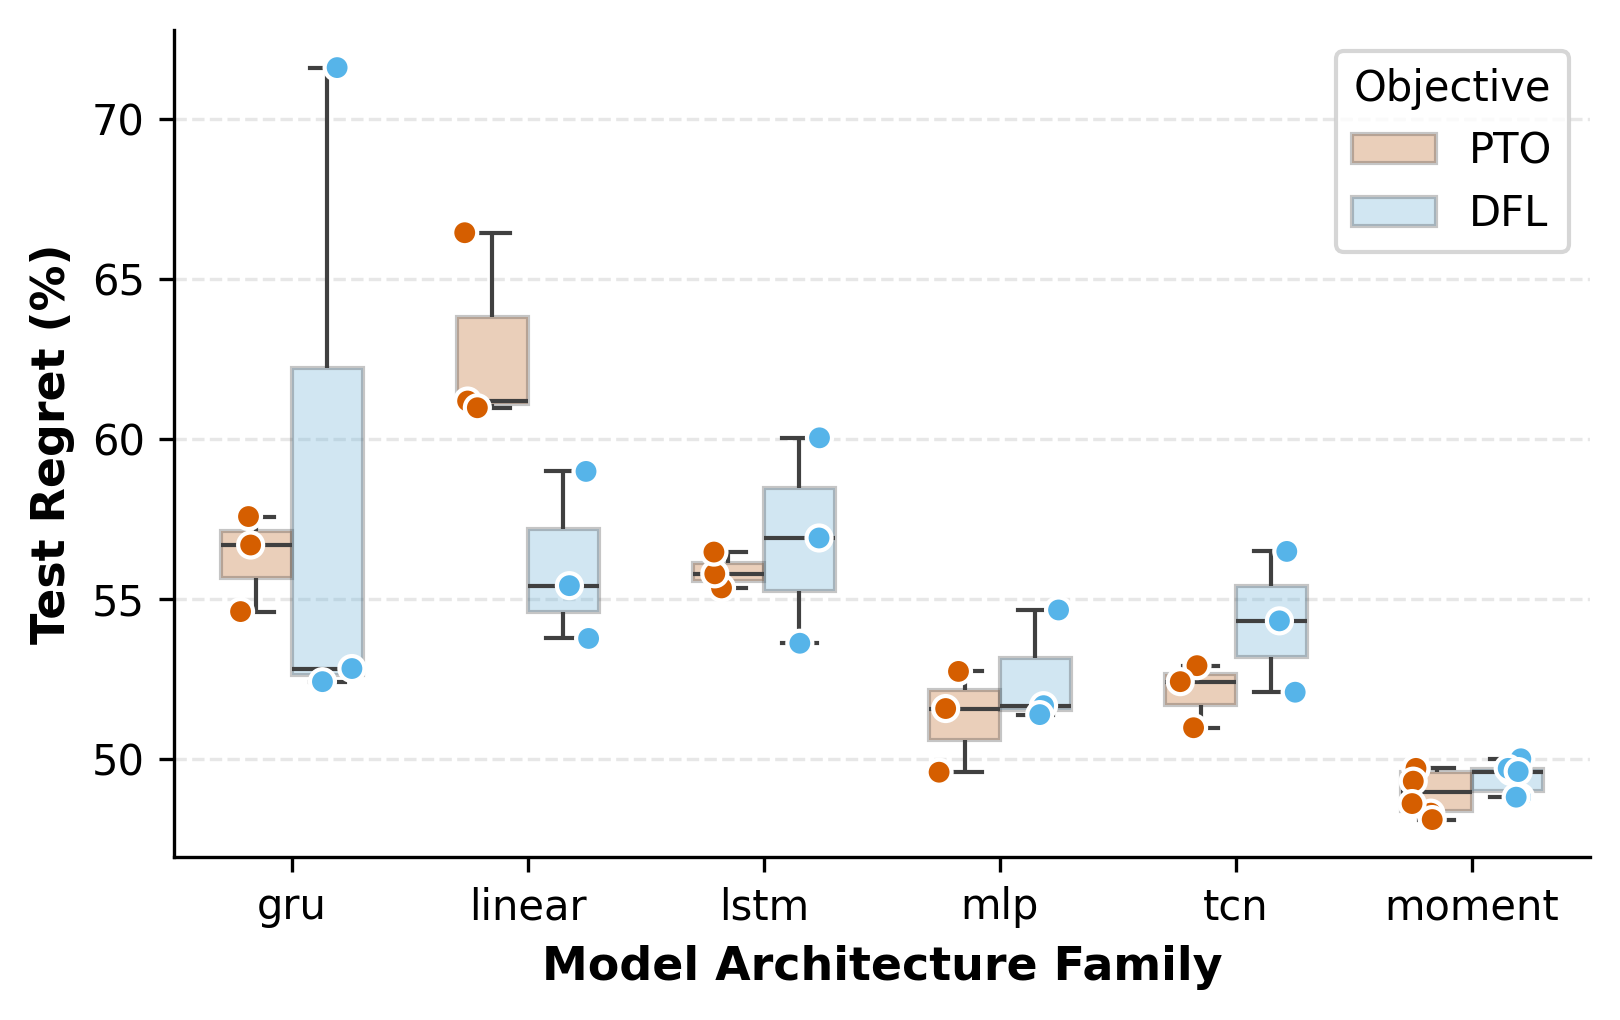

In [61]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure plots directory exists
os.makedirs("plots", exist_ok=True)

def generate_latex_table(df, row_mega, row_mega_order, row_sub, row_sub_order, title, is_tsfm=False):
    latex = f"\\begin{{table}}[h]\n\\centering\n\\caption{{{title}}}\n"
    latex += "\\resizebox{\\textwidth}{!}{\n"
    
    # 3 header columns (Mega, Sub, Obj) + 9 data columns (Train, Val, Test x 3 metrics)
    latex += "\\begin{tabular}{lll | ccc | ccc | ccc}\n\\toprule\n"
    latex += f"\\textbf{{{row_mega.capitalize()}}} & \\textbf{{{row_sub.capitalize()}}} & \\textbf{{Obj}} & \\multicolumn{{3}}{{c|}}{{\\textbf{{Train}}}} & \\multicolumn{{3}}{{c|}}{{\\textbf{{Validation}}}} & \\multicolumn{{3}}{{c}}{{\\textbf{{Test}}}} \\\\\n"
    latex += "\\cmidrule(lr){4-6} \\cmidrule(lr){7-9} \\cmidrule(lr){10-12}\n"
    latex += "& & & MSE & Profit & Regret & MSE & Profit & Regret & MSE & Profit & Regret \\\\\n"
    latex += "\\midrule\n"
    def fmt(v, metric):
        if pd.isna(v): return "-"
        if 'mse' in metric: return f"{v:.2f}"
        if 'profit' in metric: return f"{v:.2f}"
        return f"{v:.2f}"

    for mega in row_mega_order:
        mega_first = True
        for sub in row_sub_order:
            # Rename sub-methods for TSFM as requested
            if not mega_first:
                latex += "\\cmidrule(lr){2-12}\n"
            if is_tsfm:
                if sub == 'zeroshot': sub_disp = "Zero-Shot"
                elif sub == 'finetuned': sub_disp = "Moment-Head"
                elif sub == 'lora': sub_disp = "Moment-LoRA"
                else: sub_disp = sub.capitalize()
            else:
                sub_disp = sub.capitalize()
            
            is_zs = (is_tsfm and sub == 'zeroshot')
            
            row_pto = df[(df[row_mega]==mega) & (df[row_sub]==sub) & (df['obj']=='PTO')]
            row_dfl = df[(df[row_mega]==mega) & (df[row_sub]==sub) & (df['obj']=='DFL')]
            
            metrics_pto = []
            metrics_dfl = []
            
            for split in ['train', 'val', 'test']:
                for metric in ['mse', 'profit', 'regret']:
                    v_pto = row_pto.iloc[0][f"{split}_{metric}"] if len(row_pto) > 0 else np.nan
                    v_dfl = row_dfl.iloc[0][f"{split}_{metric}"] if len(row_dfl) > 0 else np.nan
                    
                    s_pto = fmt(v_pto, metric)
                    s_dfl = fmt(v_dfl, metric)
                    
                    # Bold the better value if both exist
                    if not is_zs and not pd.isna(v_pto) and not pd.isna(v_dfl):
                        if 'regret' in metric:
                        # if 'mse' in metric or 'regret' in metric:
                            # Lower is better
                            if v_pto < v_dfl: s_pto = f"\\textbf{{{s_pto}}}"
                            elif v_dfl < v_pto: s_dfl = f"\\textbf{{{s_dfl}}}"
                        # elif 'profit' in metric:
                        #     # Higher is better
                        #     if v_pto > v_dfl: s_pto = f"\\textbf{{{s_pto}}}"
                        #     elif v_dfl > v_pto: s_dfl = f"\\textbf{{{s_dfl}}}"
                            
                    metrics_pto.append(s_pto)
                    metrics_dfl.append(s_dfl)
            
            # Only print the Mega name on the first row of its block
            mega_str = mega.capitalize() if mega_first else ""
            
            if is_zs:
                # Print single row for Zero-Shot with blank objective
                latex += f"{mega_str} & {sub_disp} & & {' & '.join(metrics_pto)} \\\\\n"
            else:
                # Print PTO and DFL rows
                latex += f"{mega_str} & {sub_disp} & PTO & {' & '.join(metrics_pto)} \\\\\n"
                latex += f" & & DFL & {' & '.join(metrics_dfl)} \\\\\n"
            
            mega_first = False
        latex += "\\midrule\n"
        
    latex += "\\bottomrule\n\\end{tabular}\n}\n"
    latex += "\\end{table}\n"
    return latex


# print("==== 1. TSFM TABLE (LaTeX) ====")
df_t = df_tsfm[df_tsfm['model'].str.contains('moment')].copy()

def get_tsfm_info(m):
    size = 'small' if 'small' in m else ('large' if 'large' in m else 'base')
    dfl = '-decision' in m
    method = 'zeroshot' if 'zeroshot' in m else ('lora' if 'lora' in m else 'finetuned')
    return size, method, 'DFL' if dfl else 'PTO'

if not df_t.empty:
    df_t['size'], df_t['method'], df_t['obj'] = zip(*df_t['model'].map(get_tsfm_info))
    print(generate_latex_table(
        df_t, 'size', ['small', 'base', 'large'], 'method', ['zeroshot', 'finetuned', 'lora'], 
        "Time-Series Foundation Models (MOMENT) Performance", is_tsfm=True
    ))


# print("\n==== 2. NON-TSFM TABLE (LaTeX) ====")
df_nt = df_nontsfm_best.copy()

def get_nt_info(m):
    parts = m.replace('-decision','').split('-')
    fam = parts[0]
    size = parts[1]
    dfl = '-decision' in m
    return fam, size, 'DFL' if dfl else 'PTO'
    
if not df_nt.empty:
    df_nt['family'], df_nt['size'], df_nt['obj'] = zip(*df_nt['model'].map(get_nt_info))
    print(generate_latex_table(
        df_nt, 'family', ['linear', 'mlp', 'lstm', 'gru', 'tcn'], 'size', ['small', 'base', 'large'], 
        "Traditional Baselines Performance", is_tsfm=False
    ))


# print("\n==== 3. DISTRIBUTION PLOT (Box + Strip for N=3) ====")
df_v_nt = df_nontsfm_best.copy()
df_v_t = df_tsfm.copy()

if not df_v_nt.empty:
    df_v_nt['family'], _, df_v_nt['obj'] = zip(*df_v_nt['model'].map(get_nt_info))

if not df_v_t.empty:
    df_v_t['family'] = df_v_t['model'].apply(lambda x: x.split('-')[0])
    df_v_t['obj'] = df_v_t['model'].apply(lambda x: 'DFL' if '-decision' in x else 'PTO')
    df_v_t = df_v_t[~df_v_t['model'].str.contains('zeroshot')]

df_v_all = pd.concat([df_v_nt, df_v_t], ignore_index=True)
df_v_all = df_v_all.dropna(subset=['test_regret'])

if not df_v_all.empty:
    plt.figure(figsize=(5.5, 3.5), dpi=300)
    
    palette_dict = {'PTO': '#D55E00', 'DFL': '#56B4E9'}
    
    # 1. Boxplot (Semi-transparent) to show median and IQR range
    sns.boxplot(
        data=df_v_all, 
        x='family', 
        y='test_regret', 
        hue='obj', 
        palette=palette_dict,
        width=0.6,
        fliersize=0, # Hide standard outliers so stripplot handles them
        boxprops=dict(alpha=0.3) # Make boxes transparent
    )
    
    # 2. Stripplot overlaid to show the EXACT data points per group
    sns.stripplot(
        data=df_v_all, 
        x='family', 
        y='test_regret', 
        hue='obj', 
        palette=palette_dict,
        dodge=True,  # Align strips with boxes
        jitter=0.15, # Slight horizontal noise so points don't perfectly overlap
        size=6,
        linewidth=1,
        edgecolor='white'
    )
    
    plt.xlabel('Model Architecture Family', fontsize=11, fontweight='bold')
    plt.ylabel('Test Regret (%)', fontsize=11, fontweight='bold')
    # plt.title('Distribution of Test Regret across Architectures (PTO vs. DFL)', fontsize=12)
    plt.grid(alpha=0.3, axis='y', linestyle='--')
    
    # Clean up duplicate legends caused by combining two seaborn plots
    handles, labels = plt.gca().get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], title='Objective', loc='best', fancybox=True)
    
    # Hide top and right spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.savefig("plots/regret_vs_model.pdf", format='pdf', bbox_inches='tight')
    plt.show()